# Machine Learning Assignment
## Mini Project 3 — Iris Flower Clustering and PCA

**Submitted by:** Mayank Kumar Dubey  
**Branch:** B.Tech AIML  
**Semester:** 5th Semester  

### Mini Project 3
**Iris Flower Clustering Project**  
**Dataset:** Iris Dataset (UCI / Scikit-learn)

### Tasks
1. Perform K-Means on Iris dataset and visualize clusters.
2. Apply PCA to reduce dataset dimensions.
3. Compare predicted clusters with true labels.

## 1. Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_score

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Iris Dataset

The Iris dataset contains 150 flower samples, four numerical measurements, and three actual species labels.

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y_true = iris.target

df = X.copy()
df["Actual Species"] = pd.Categorical.from_codes(
    y_true, categories=iris.target_names
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (150, 5)


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Actual Species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Explore the Dataset

In [3]:
print("Dataset information:")
print(X.info())

print("\nStatistical summary:")
display(X.describe())

print("\nActual species distribution:")
print(df["Actual Species"].value_counts())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   sepal length (cm)  150 non-null    float64
 1   sepal width (cm)   150 non-null    float64
 2   petal length (cm)  150 non-null    float64
 3   petal width (cm)   150 non-null    float64
dtypes: float64(4)
memory usage: 4.8 KB
None

Statistical summary:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000



Actual species distribution:
Actual Species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


## 4. Data Preprocessing — Feature Scaling

K-Means uses distance calculations. StandardScaler puts the four features on a comparable scale.

In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature scaling completed.")
print("Scaled data shape:", X_scaled.shape)

Feature scaling completed.
Scaled data shape: (150, 4)


## 5. Apply K-Means Clustering (K = 3)

The model is trained without using the actual species labels. It discovers three groups from the feature measurements.

In [5]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

predicted_clusters = kmeans.fit_predict(X_scaled)
df["Predicted Cluster"] = predicted_clusters

print("K-Means clustering completed successfully.")
print("\nFirst 10 predicted cluster labels:")
print(predicted_clusters[:10])

print("\nCluster sizes:")
print(df["Predicted Cluster"].value_counts().sort_index())

K-Means clustering completed successfully.

First 10 predicted cluster labels:
[1 1 1 1 1 1 1 1 1 1]

Cluster sizes:
Predicted Cluster
0    53
1    50
2    47
Name: count, dtype: int64


## 6. Apply PCA to Reduce Dataset Dimensions

PCA reduces the four original features to two principal components. These two components can be plotted on a 2D graph while retaining as much variance as possible.

In [6]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

print("Original number of features:", X_scaled.shape[1])
print("Reduced number of features:", X_pca.shape[1])
print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total variance retained:", round(pca.explained_variance_ratio_.sum(), 4))

Original number of features: 4
Reduced number of features: 2
Explained variance ratio: [0.72962445 0.22850762]
Total variance retained: 0.9581


## 7. Visualize K-Means Clusters Using PCA

The clusters were learned using all four scaled features. PCA is used here only to display those four-dimensional observations in two dimensions.

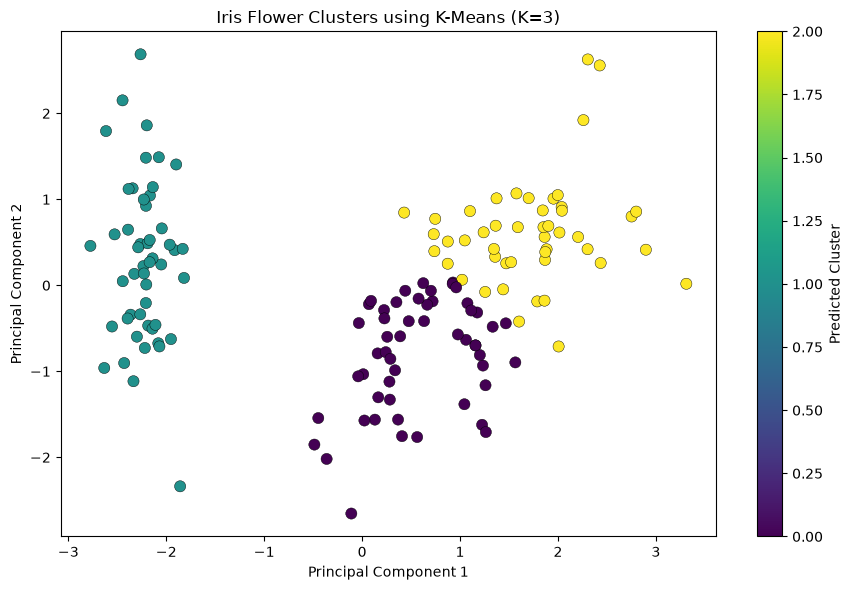

In [7]:
plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=predicted_clusters,
    cmap="viridis",
    s=65,
    edgecolor="black",
    linewidth=0.3
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Iris Flower Clusters using K-Means (K=3)")
plt.colorbar(scatter, label="Predicted Cluster")
plt.tight_layout()
plt.show()

## 8. Compare Predicted Clusters with True Labels

Cluster IDs are arbitrary and do not automatically correspond to species IDs. A cross-tabulation shows how the actual species are distributed across the predicted clusters.

In [8]:
comparison = pd.crosstab(
    pd.Series(y_true, name="Actual Species"),
    pd.Series(predicted_clusters, name="Predicted Cluster")
)

comparison.index = iris.target_names[comparison.index]

print("Actual Species vs Predicted Clusters:")
display(comparison)

ari = adjusted_rand_score(y_true, predicted_clusters)
print("Adjusted Rand Index (ARI):", round(ari, 4))

Actual Species vs Predicted Clusters:


Predicted Cluster,0,1,2
setosa,0,50,0
versicolor,39,0,11
virginica,14,0,36


Adjusted Rand Index (ARI): 0.6201


## 9. Visualize Actual Labels vs Predicted Clusters

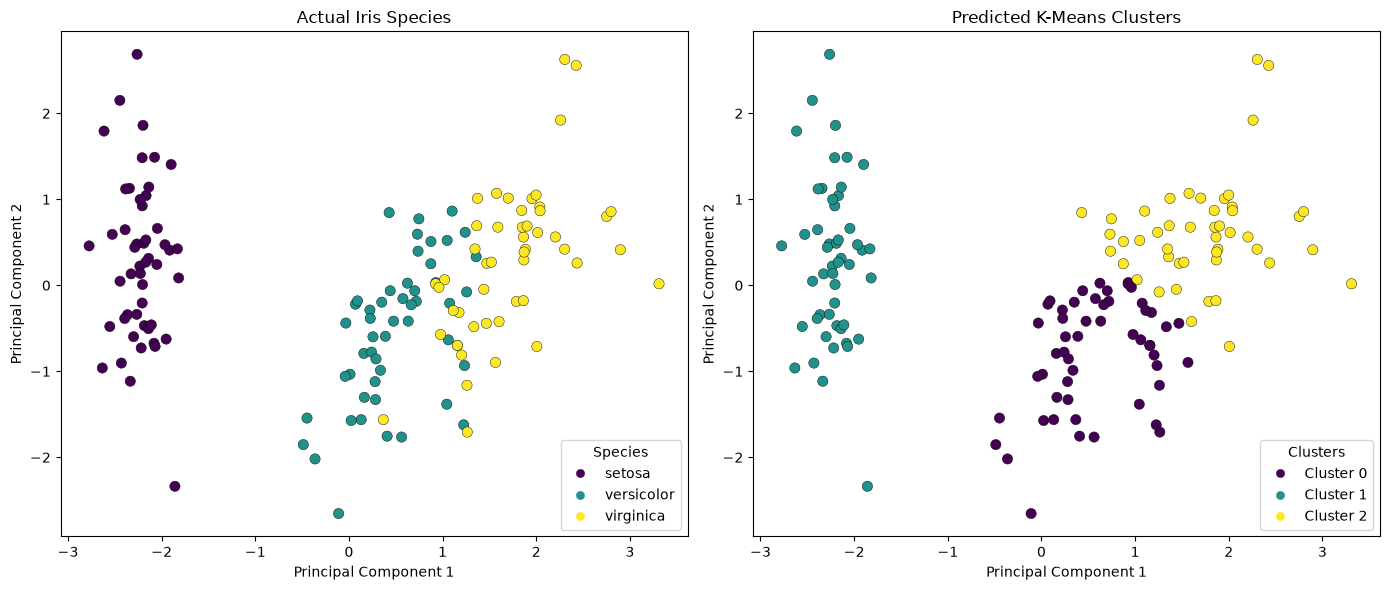

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

actual_plot = axes[0].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=y_true, cmap="viridis", s=55,
    edgecolor="black", linewidth=0.3
)
axes[0].set_title("Actual Iris Species")
axes[0].set_xlabel("Principal Component 1")
axes[0].set_ylabel("Principal Component 2")
axes[0].legend(
    handles=actual_plot.legend_elements()[0],
    labels=list(iris.target_names),
    title="Species"
)

cluster_plot = axes[1].scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=predicted_clusters, cmap="viridis", s=55,
    edgecolor="black", linewidth=0.3
)
axes[1].set_title("Predicted K-Means Clusters")
axes[1].set_xlabel("Principal Component 1")
axes[1].set_ylabel("Principal Component 2")
axes[1].legend(
    handles=cluster_plot.legend_elements()[0],
    labels=["Cluster 0", "Cluster 1", "Cluster 2"],
    title="Clusters"
)

plt.tight_layout()
plt.show()

## 10. Clustering Evaluation

The Adjusted Rand Index (ARI) compares the predicted grouping with the known species labels while accounting for arbitrary cluster numbering. A score of 1 indicates perfect agreement; a score near 0 indicates agreement similar to random grouping.

In [10]:
print("Adjusted Rand Index:", round(ari, 4))
print("Silhouette Score:", round(silhouette_score(X_scaled, predicted_clusters), 4))

Adjusted Rand Index: 0.6201
Silhouette Score: 0.4599


## 11. Conclusion

In this project, K-Means clustering was applied to the Iris dataset with **K = 3**. The four numerical features were standardized before clustering because K-Means is distance-based.

PCA was then used to reduce the four-dimensional dataset to two principal components for visualization. The predicted clusters were compared with the actual Iris species using a cross-tabulation and Adjusted Rand Index.

**Result:** The project demonstrates unsupervised learning with K-Means and dimensionality reduction with PCA. The cluster labels are group identifiers and are not automatically the same as the actual species labels.